# Cancelamentos e devoluções em e-commerce: análise exploratória e modelo preditivo

**Projeto de parceria (EBAC × Semantix): Analista de Dados**

## O problema
Em um e-commerce, itens cancelados ou devolvidos representam receita perdida, custo logístico e desgaste com o cliente. Nesta base, cerca de **um quarto de todos os itens vendidos** termina assim.

**Pergunta do projeto:** dá para identificar, com informações conhecidas **no momento da compra**, quais itens têm maior risco de serem cancelados ou devolvidos, e quais perfis (categoria, canal, país, faixa etária, preço) concentram esse risco?

## Por que usar dados
Sem dados, o time só enxerga o problema depois que ele acontece. Com dados, é possível (1) localizar onde o risco se concentra, (2) priorizar ações de prevenção e (3) medir se um modelo consegue antecipar o desfecho de forma útil.

## Fonte de dados
Dataset público `bigquery-public-data.thelook_ecommerce` (Google BigQuery), com as tabelas `order_items`, `products` e `users`, tratadas e unidas na tabela `vendas_analise` (181.087 linhas, 23 colunas). O tratamento está em `consultas_ecommerce.sql`.

> **Atenção:** é um dataset **sintético** (gerado para fins didáticos). Os padrões encontrados não representam uma loja real, e isso é considerado na interpretação dos resultados.

## 0. Configuração

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
os.makedirs("figuras", exist_ok=True)
pd.set_option("display.max_columns", 30)

# "bigquery" lê direto da tabela tratada; "csv" lê o arquivo base_tratada.csv (enviado ao Colab ou na pasta do notebook)
FONTE = "bigquery"

## 1. Carregamento dos dados

In [2]:
if FONTE == "bigquery":
    from google.colab import auth
    auth.authenticate_user()
    from google.cloud import bigquery
    client = bigquery.Client(project="modulogcloud")
    df = client.query("SELECT * FROM `modulogcloud.ecommerce_analise.vendas_analise`").to_dataframe()
else:
    df = pd.read_csv("base_tratada.csv")

df["data_pedido"] = pd.to_datetime(df["data_pedido"])
print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (181087, 23)


,item_id,pedido_id,data_pedido,ano_mes,ano,status,categoria,departamento,marca,custo,preco_venda,margem,margem_pct,dias_ate_envio,dias_ate_entrega,foi_entregue,foi_devolvido,cliente_id,faixa_etaria,genero,pais,estado,canal
0,162457,111987,2019-06-10,2019-06,2019,Cancelled,Accessories,Women,Gem Avenue,8.90,19.99,11.09,55.5,<NA>,<NA>,False,False,89678,0-24,Feminino,South Korea,Gyeonggi-do,Search
1,26429,18237,2019-07-05,2019-07,2019,Cancelled,Underwear,Men,Wolverine,11.05,25.00,13.95,55.8,<NA>,<NA>,False,False,14643,55+,Masculino,United States,Louisiana,Search
2,97581,67300,2019-08-15,2019-08,2019,Cancelled,Tops & Tees,Men,Champion,10.28,19.59,9.31,47.5,<NA>,<NA>,False,False,53879,55+,Masculino,United Kingdom,England,Facebook
3,78894,54433,2019-09-22,2019-09,2019,Cancelled,Sweaters,Men,A:X Armani Exchange,61.95,128.00,66.05,51.6,<NA>,<NA>,False,False,43654,25-34,Masculino,Brazil,Paraná,Search
4,60376,41626,2019-11-05,2019-11,2019,Cancelled,Plus,Women,Gold Toe,7.88,15.00,7.12,47.5,<NA>,<NA>,False,False,33354,25-34,Feminino,United States,Massachusetts,Search


In [3]:
df.info()
print()
print("Nulos por coluna (somente colunas com nulos):")
nulos = df.isna().sum()
print(nulos[nulos > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181087 entries, 0 to 181086
Data columns (total 23 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   item_id           181087 non-null  Int64         
 1   pedido_id         181087 non-null  Int64         
 2   data_pedido       181087 non-null  datetime64[ns]
 3   ano_mes           181087 non-null  object        
 4   ano               181087 non-null  Int64         
 5   status            181087 non-null  object        
 6   categoria         181087 non-null  object        
 7   departamento      181087 non-null  object        
 8   marca             180946 non-null  object        
 9   custo             181087 non-null  float64       
 10  preco_venda       181087 non-null  float64       
 11  margem            181087 non-null  float64       
 12  margem_pct        181087 non-null  float64       
 13  dias_ate_envio    118229 non-null  Int64         
 14  dias

## 2. Definição do alvo e do escopo da modelagem

O alvo é `perdido`: **1** se o item foi **cancelado ou devolvido**, **0** se foi concluído (`Complete`).

Itens ainda em `Processing` ou `Shipped` **ficam de fora da modelagem**: o desfecho deles ainda não é conhecido, e tratá-los como "não perdidos" criaria rótulos falsos.

In [4]:
print("Distribuição de status (todos os itens):")
print(df["status"].value_counts(), "\n")

fechados = ["Complete", "Cancelled", "Returned"]
df_m = df[df["status"].isin(fechados)].copy()
df_m["perdido"] = df_m["status"].isin(["Cancelled", "Returned"]).astype(int)

taxa_global = df_m["perdido"].mean()
print(f"Itens com desfecho conhecido: {len(df_m):,}")
print(f"Taxa de perda (cancelado/devolvido) entre eles: {taxa_global:.1%}")
print(f"Taxa de perda considerando TODOS os itens da base: "
      f"{df['status'].isin(['Cancelled','Returned']).mean():.1%}")

Distribuição de status (todos os itens):
status
Shipped       54673
Complete      45461
Processing    36122
Cancelled     26736
Returned      18095
Name: count, dtype: int64 

Itens com desfecho conhecido: 90,292
Taxa de perda (cancelado/devolvido) entre eles: 49.7%
Taxa de perda considerando TODOS os itens da base: 24.8%


## 3. Análise exploratória: onde o risco se concentra?
Taxa de perda por segmento, comparada com a média geral (linha vermelha).

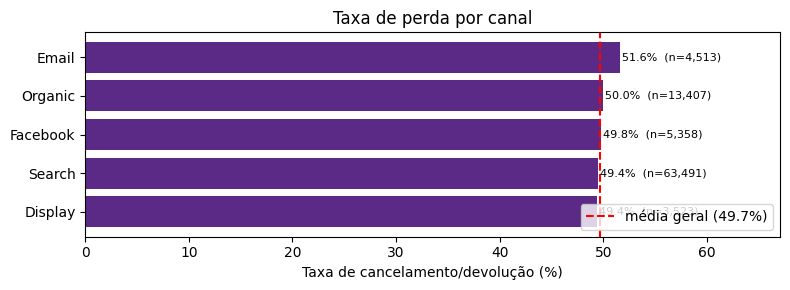

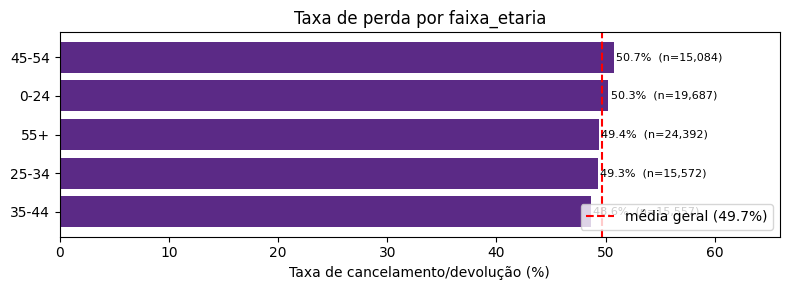

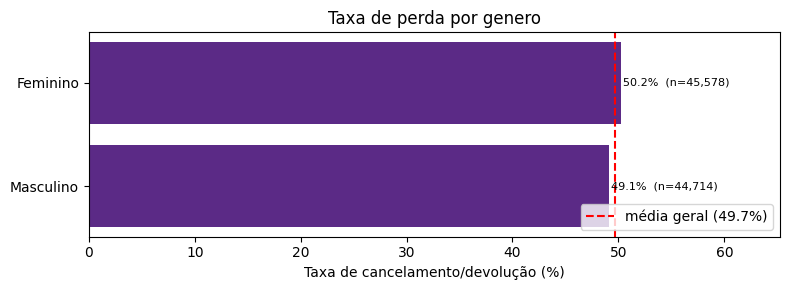

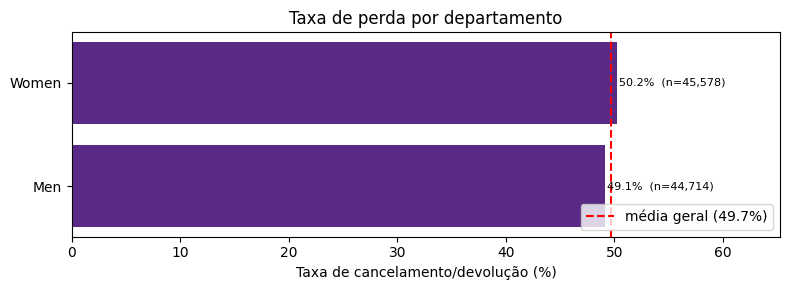

In [5]:
def taxa_por(col, top=None, ordem="taxa", titulo=None):
    t = (df_m.groupby(col)["perdido"].agg(taxa="mean", itens="count"))
    if top:
        t = t.sort_values("itens", ascending=False).head(top)
    t = t.sort_values("taxa" if ordem == "taxa" else col)
    fig, ax = plt.subplots(figsize=(8, max(3, 0.38 * len(t))))
    ax.barh(t.index.astype(str), t["taxa"] * 100, color="#5b2a86")
    ax.axvline(taxa_global * 100, color="red", ls="--", label=f"média geral ({taxa_global:.1%})")
    for i, (v, n) in enumerate(zip(t["taxa"], t["itens"])):
        ax.text(v * 100 + 0.2, i, f"{v:.1%}  (n={n:,})", va="center", fontsize=8)
    ax.set_xlabel("Taxa de cancelamento/devolução (%)")
    ax.set_title(titulo or f"Taxa de perda por {col}")
    ax.set_xlim(0, max(t["taxa"].max() * 100 * 1.3, taxa_global * 100 * 1.3))
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(f"figuras/taxa_perda_{col}.png", dpi=150)
    plt.show()
    return t

for c in ["canal", "faixa_etaria", "genero", "departamento"]:
    taxa_por(c)

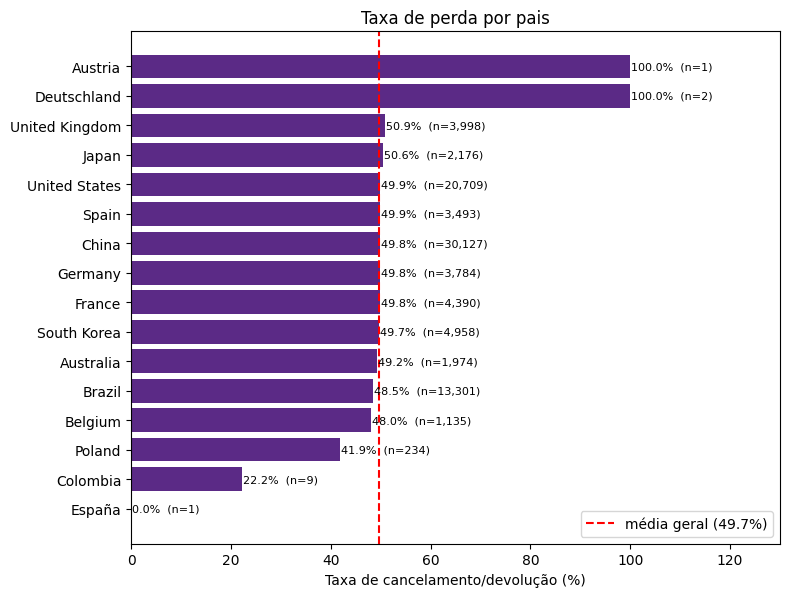

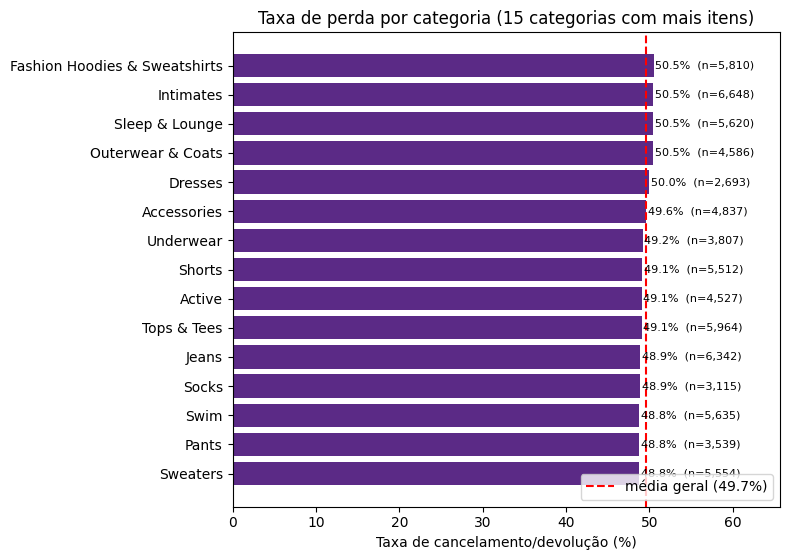

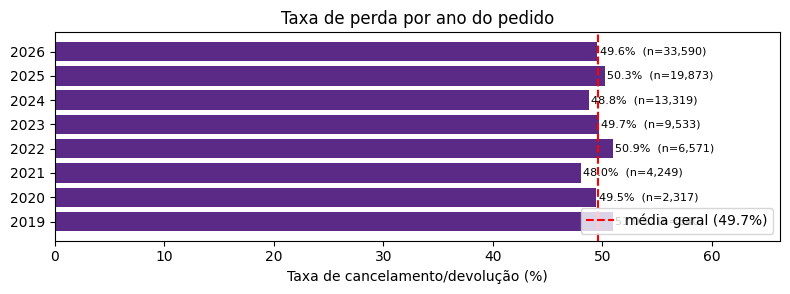

In [6]:
_ = taxa_por("pais")
_ = taxa_por("categoria", top=15, titulo="Taxa de perda por categoria (15 categorias com mais itens)")
_ = taxa_por("ano", ordem="indice", titulo="Taxa de perda por ano do pedido")

/tmp/ipykernel_15708/2836891451.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  t = (df_m.groupby(col)["perdido"].agg(taxa="mean", itens="count"))


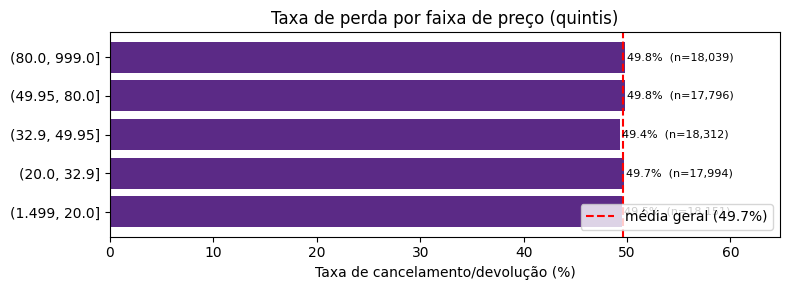

In [7]:
# Preço: faixas por quintil
df_m["faixa_preco"] = pd.qcut(df_m["preco_venda"], 5, duplicates="drop")
_ = taxa_por("faixa_preco", ordem="indice", titulo="Taxa de perda por faixa de preço (quintis)")

### Variáveis importantes e correlações
- **Numéricas:** correlação com o alvo.
- **Categóricas:** associação com o alvo pelo **V de Cramér** (0 = nenhuma associação, 1 = associação total).

Correlação das variáveis numéricas com o alvo:
preco_venda    0.0018
custo          0.0011
margem_pct     0.0001
ano            0.0007
Name: perdido, dtype: float64 

V de Cramér (associação com o alvo):
canal             0.0097
departamento      0.0110
genero            0.0110
faixa_etaria      0.0141
categoria         0.0156
marca_agrupada    0.0158
pais              0.0165
dtype: float64


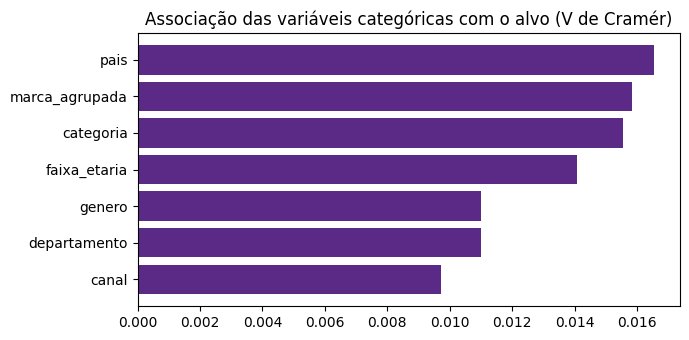

In [8]:
df_m["marca_agrupada"] = df_m["marca"].where(df_m["marca"].isin(df_m["marca"].value_counts().head(30).index), "Outras")

num = ["preco_venda", "custo", "margem_pct", "ano"]
print("Correlação das variáveis numéricas com o alvo:")
print(df_m[num + ["perdido"]].corr()["perdido"].drop("perdido").round(4), "\n")

def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

cats = ["categoria", "departamento", "marca_agrupada", "faixa_etaria", "genero", "pais", "canal"]
cv = pd.Series({c: cramers_v(df_m[c], df_m["perdido"]) for c in cats}).sort_values()
print("V de Cramér (associação com o alvo):")
print(cv.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cv.index, cv.values, color="#5b2a86")
ax.set_title("Associação das variáveis categóricas com o alvo (V de Cramér)")
plt.tight_layout(); plt.savefig("figuras/cramers_v.png", dpi=150); plt.show()

## 4. Preparação das variáveis para o modelo

**Só entram variáveis conhecidas no momento da compra.** Ficam de fora, de propósito, as colunas que só existem depois do desfecho e "entregariam" a resposta (**vazamento de dados**): `foi_devolvido`, `foi_entregue`, `dias_ate_envio` e `dias_ate_entrega`.

Divisão **80% treino / 20% teste**, estratificada pelo alvo.

In [9]:
df_m["mes"] = df_m["data_pedido"].dt.month
df_m["dia_semana"] = df_m["data_pedido"].dt.dayofweek

num_feats = ["preco_venda", "custo", "margem_pct", "ano", "mes", "dia_semana"]
cat_feats = ["categoria", "departamento", "marca_agrupada", "faixa_etaria", "genero", "pais", "canal"]

X = df_m[num_feats + cat_feats]
y = df_m["perdido"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Treino: {len(X_tr):,} linhas | Teste: {len(X_te):,} linhas")
print(f"Taxa de perda no treino: {y_tr.mean():.1%} | no teste: {y_te.mean():.1%}")

Treino: 72,233 linhas | Teste: 18,059 linhas
Taxa de perda no treino: 49.7% | no teste: 49.6%


## 5. Modelagem

Três modelos, do mais simples ao mais flexível:
1. **Baseline** (sempre prevê a classe mais comum): o piso de comparação.
2. **Regressão logística**: modelo estatístico interpretável.
3. **Random Forest**: modelo de machine learning que captura relações não lineares.

A métrica principal é a **AUC-ROC** (0,5 = acerto ao acaso; 1,0 = perfeito).

In [10]:
prep = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), cat_feats),
])

modelos = {
    "Baseline (classe mais comum)": DummyClassifier(strategy="prior"),
    "Regressão logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                            n_jobs=-1, random_state=SEED),
}

pipes, linhas = {}, []
for nome, mdl in modelos.items():
    pipe = Pipeline([("prep", prep), ("modelo", mdl)]).fit(X_tr, y_tr)
    pipes[nome] = pipe
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    linhas.append({
        "modelo": nome,
        "acurácia": accuracy_score(y_te, pred),
        "precisão": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "F1": f1_score(y_te, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_te, proba),
    })

resultados = pd.DataFrame(linhas).set_index("modelo").round(4)
resultados

,acurácia,precisão,recall,F1,AUC-ROC
modelo,,,,,
Baseline (classe mais comum),0.5035,0.000,0.0000,0.0000,0.5000
Regressão logística,0.5060,0.503,0.4175,0.4563,0.5070
Random Forest,0.5163,0.518,0.3701,0.4317,0.5166


In [11]:
# Validação cruzada (3 partes) no treino: o desempenho é estável ou foi sorte da divisão?
cv_res = {}
for nome in ["Regressão logística", "Random Forest"]:
    sc = cross_val_score(pipes[nome], X_tr, y_tr, cv=3, scoring="roc_auc", n_jobs=-1)
    cv_res[nome] = sc
    print(f"{nome}: AUC por parte = {np.round(sc, 4)} | média = {sc.mean():.4f} (desvio {sc.std():.4f})")

Regressão logística: AUC por parte = [0.5016 0.5038 0.5034] | média = 0.5030 (desvio 0.0009)
Random Forest: AUC por parte = [0.5029 0.5039 0.5075] | média = 0.5047 (desvio 0.0020)


### Avaliação do melhor modelo

Melhor modelo pela AUC: Random Forest


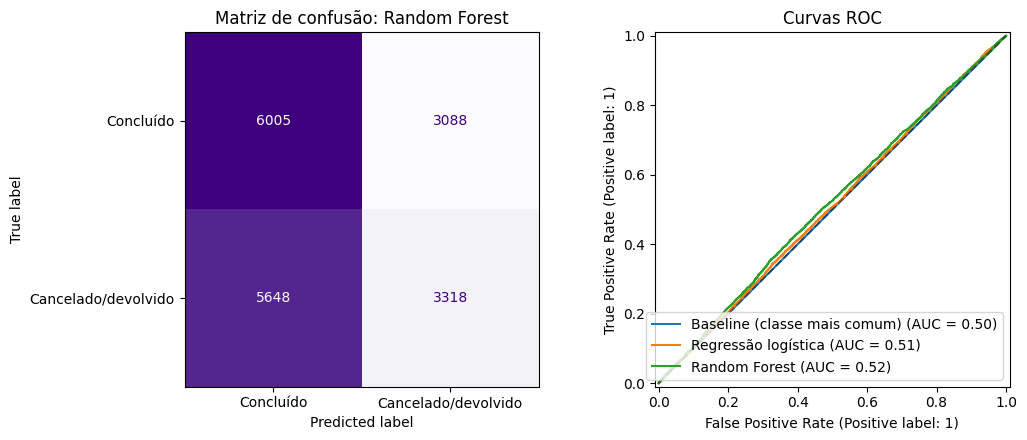

In [12]:
melhor = resultados["AUC-ROC"].idxmax()
print("Melhor modelo pela AUC:", melhor)
pipe = pipes[melhor]

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_estimator(pipe, X_te, y_te, display_labels=["Concluído", "Cancelado/devolvido"],
                                      cmap="Purples", ax=axs[0], colorbar=False)
axs[0].set_title(f"Matriz de confusão: {melhor}")
for nome, p in pipes.items():
    RocCurveDisplay.from_estimator(p, X_te, y_te, name=nome, ax=axs[1])
axs[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axs[1].set_title("Curvas ROC")
plt.tight_layout(); plt.savefig("figuras/avaliacao_modelo.png", dpi=150); plt.show()

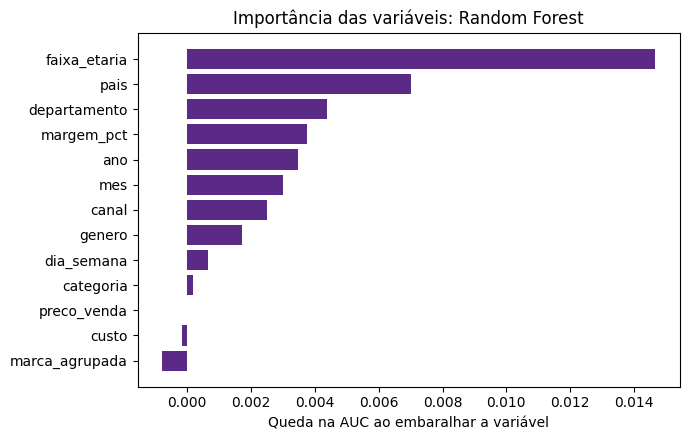

faixa_etaria      0.01467
pais              0.00702
departamento      0.00437
margem_pct        0.00376
ano               0.00346
mes               0.00300
canal             0.00250
genero            0.00171
dia_semana        0.00066
categoria         0.00016
preco_venda      -0.00001
custo            -0.00016
marca_agrupada   -0.00078
dtype: float64


In [13]:
# Importância por permutação (quanto a AUC cai quando a variável é embaralhada), em amostra do teste
amostra = X_te.sample(min(8000, len(X_te)), random_state=SEED)
res = permutation_importance(pipe, amostra, y_te.loc[amostra.index], scoring="roc_auc",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(res.importances_mean, index=amostra.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.index, imp.values, color="#5b2a86")
ax.set_xlabel("Queda na AUC ao embaralhar a variável")
ax.set_title(f"Importância das variáveis: {melhor}")
plt.tight_layout(); plt.savefig("figuras/importancia_variaveis.png", dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(5))

## 6. Resumo automático dos resultados

In [14]:
auc_base = resultados.loc["Baseline (classe mais comum)", "AUC-ROC"]
auc_melhor = resultados.loc[melhor, "AUC-ROC"]
acc_melhor = resultados.loc[melhor, "acurácia"]
acc_base = resultados.loc["Baseline (classe mais comum)", "acurácia"]

print(f"Taxa de perda entre itens com desfecho conhecido: {taxa_global:.1%}")
print(f"Melhor modelo: {melhor}")
print(f"  AUC-ROC: {auc_melhor:.3f} (baseline = {auc_base:.3f})")
print(f"  Acurácia: {acc_melhor:.1%} (baseline = {acc_base:.1%})")
print(f"  Variável mais importante: {imp.sort_values(ascending=False).index[0]}")
if auc_melhor < 0.6:
    print("\nLeitura: o modelo é só um pouco melhor que o acaso. Nesta base sintética, as variáveis "
          "conhecidas na compra explicam pouco do cancelamento/devolução.")
else:
    print("\nLeitura: o modelo consegue separar itens de maior e menor risco de forma útil.")

resultados.to_csv("resultados_modelos.csv")
print("\nArquivos salvos: resultados_modelos.csv e a pasta figuras/")

Taxa de perda entre itens com desfecho conhecido: 49.7%
Melhor modelo: Random Forest
  AUC-ROC: 0.517 (baseline = 0.500)
  Acurácia: 51.6% (baseline = 50.3%)
  Variável mais importante: faixa_etaria

Leitura: o modelo é só um pouco melhor que o acaso. Nesta base sintética, as variáveis conhecidas na compra explicam pouco do cancelamento/devolução.

Arquivos salvos: resultados_modelos.csv e a pasta figuras/


In [15]:
# (Colab) baixar os resultados e as figuras
try:
    import shutil
    from google.colab import files
    shutil.make_archive("figuras", "zip", "figuras")
    files.download("resultados_modelos.csv")
    files.download("figuras.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>